# Hybrid generative models of the brain
### From physics-based to data-driven models

**Daniel López-Montero** — joint work with Lorenzo Liverani, Enrique Zuazua and Xenia Kobeleva<br>
Chair for Dynamics, Control, Machine Learning and Numerics (Alexander von Humboldt Professorship), FAU Erlangen-Nürnberg

![From brain scans to a fitted brain model](img/workflow.jpg)

*The workflow behind this notebook: (a) a brain scan is cut into regions and turned into signals, (b) every region becomes a small oscillator wired to the others, (c) the model is tuned until its simulated activity looks like the measured one, (d) the result is tested on new data.*

Even when you lie still with your eyes closed, your brain is never quiet: billions of neurons keep up slow, coordinated waves of activity that travel between brain regions. **Can we write equations that reproduce this activity?** And if we can, can we trust them enough to one day test a treatment on a *virtual copy* of a patient's brain before trying it on the patient?

This notebook is an introduction to that question and to our recent work on **hybrid models**: equations that keep the physics we trust and let a neural network learn the part we do not know. You will:

1. build a small **virtual brain** with our open-source package and watch it produce scanner-like signals;
2. see how a real-valued brain signal is turned into a **complex** one (an amplitude and a rhythm);
3. compute the fingerprint neuroscientists use most, **functional connectivity**;
4. find out, with a three-line experiment, why the most obvious way of comparing a model with data **fails**;
5. meet the three families of models (physics-based, data-driven and **hybrid**) and what they achieve on real brains.

## 0. Setup

The notebook only needs our package [`neuroscience-modeling`](https://github.com/DCN-FAU-AvH/neuroscience-modeling) (Python ≥ 3.13). In a terminal:

```bash
python3.13 -m venv .venv && source .venv/bin/activate                 # fresh environment (Windows: .venv\Scripts\activate)
pip install torch --index-url https://download.pytorch.org/whl/cpu   # optional: small CPU-only PyTorch, enough here
pip install "torchsde @ git+https://github.com/dani2442/torchsde"    # torchsde with complex-valued noise
pip install "neuroscience-control @ git+https://github.com/DCN-FAU-AvH/neuroscience-modeling"
pip install jupyterlab
jupyter lab hybrid_brain_models.ipynb
```

If you prefer [`uv`](https://docs.astral.sh/uv/): `git clone https://github.com/DCN-FAU-AvH/neuroscience-modeling && cd neuroscience-modeling && uv sync`, then start Jupyter with `uv run --with jupyterlab jupyter lab`. Keep the file `plotting.py` next to this notebook: it only draws the figures.

In [1]:
import math
import torch

from src.models import CoupledHopfModel, HybridHopfModel, NeuralSDE
from src.dataset import fft_bandpass_3d, hilbert_transform
from src.metrics import compute_static_fc, FCCorrelation, FCMSE, L2Timeseries
from src.utils import seed_all
import plotting as P
%matplotlib inline

TR = 0.72   # seconds between two consecutive brain images (as in the Human Connectome Project)
DT = 0.24   # time step of the equation solver: three steps per image

## 1. Why model a brain?

A **brain model** is a set of equations whose solutions look like recorded brain activity. Once we have one, we can use it to

* **understand** — which ingredients (anatomy, rhythms, noise) are needed to explain what we see;
* **diagnose** — fitted model parameters can serve as markers that separate healthy and diseased brains;
* **treat** — test a stimulation protocol *in silico* on a "digital twin" of a patient before applying it [26].

For this to work, a model must satisfy three requirements that pull in different directions:

| Requirement | In plain words |
|---|---|
| **Data fidelity** | its simulated activity has the same statistics ("descriptors") as the real brain |
| **Interpretability** | its parameters mean something to a neuroscientist, so the model can be trusted and checked |
| **Personalisation** | there is one model per person, trainable from the few recordings available for a single subject |

## 2. A century of brain models

![Timeline of brain modelling](img/timeline.png)


A human brain has about 86 billion neurons, far too many to simulate one by one. **Whole-brain models** zoom out [3]: they divide the cortex into $n$ regions (here, $n=100$ in the real data and $n=20$ in our toy) and describe each region by a single quantity $z_i(t)$ that evolves in time. Two classical families exist:

* **Neural mass models** — a finite system of (stochastic) ordinary differential equations, one small system per region:
$$\dot z_i = f(z_i) + \sum_{j} C_{ij}\, g(z_i, z_j).$$
* **Neural field models** — a partial differential equation on the cortical sheet $\Omega\subset\mathbb{R}^3$, treating activity as a continuous medium [7]:
$$\partial_t \psi(t,x) = -\psi(t,x) + \int_\Omega \omega(x-x')\, f\big(\psi(t,x')\big)\,\mathrm{d}x'.$$

This notebook belongs to the first family.

## 3. What does a brain scanner see?

![fMRI as a data matrix](img/fmri.gif)

*Real resting-state fMRI from the Human Connectome Project, cut into 100 regions [13, 14].*

Functional MRI does not see neurons directly. It measures the **BOLD signal** (Blood-Oxygen-Level-Dependent), a slow change in blood oxygenation that follows local neural activity with a delay of a few seconds. The cortex is divided into regions, and the scanner takes one picture of the whole brain every $\Delta t = 0.72$ s.

For a mathematician, a scanning session is simply a **multivariate time series**: a dataset is a collection of $N$ recordings

$$\mathcal{D}=\big\{x^{(k)}\big\}_{k=1}^{N},\qquad x^{(k)}:[0,T]\to\mathbb{R}^{100},$$

each with $1200$ samples (about 14 minutes). In our paper we used $N=94$ healthy young adults [1, 13].

## 4. Building a virtual brain

### 4.1 The wiring: a structural connectome

Brain regions talk to each other through bundles of nerve fibres. Diffusion MRI can trace these bundles, giving the **structural connectome**: a matrix $C$ whose entry $C_{ij}\ge 0$ says how strongly region $i$ is wired to region $j$ [25].

Our toy brain has 20 regions, 10 per hemisphere. We use two well-known facts about real connectomes: connections become weaker with distance (the *exponential distance rule* [27]), and each region is linked to its mirror image in the other hemisphere (through the *corpus callosum*).

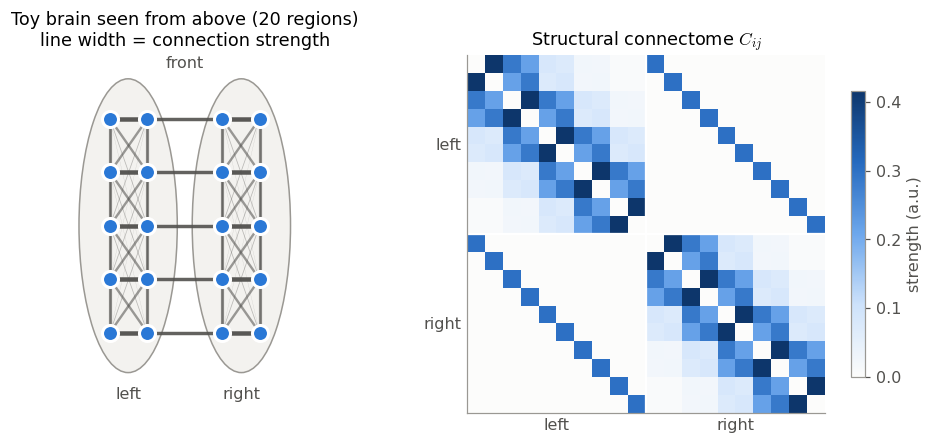

In [2]:
# 20 regions on a 5 (front -> back) x 2 (inner -> outer) grid in each hemisphere
pos = torch.tensor([(side * (0.35 + 0.35 * col), 1.0 - 0.5 * row)
                    for side in (-1, 1) for row in range(5) for col in range(2)])
same_side = pos[:, None, 0] * pos[None, :, 0] > 0
mirror = (pos[:, None, 0] == -pos[None, :, 0]) & (pos[:, None, 1] == pos[None, :, 1])

C = torch.exp(-torch.cdist(pos, pos) / 0.4) * same_side + 0.3 * mirror
C.fill_diagonal_(0)
P.connectome(pos, C)

### 4.2 One region, one oscillator: the Stuart–Landau equation

Brain activity is rhythmic, so each region is modelled by the simplest equation that can start oscillating, the **Stuart–Landau oscillator** (the *normal form of a Hopf bifurcation* [29]). Its state is a complex number $z = r\,e^{i\phi}$ (an amplitude $r$ and a phase $\phi$):

$$\dot z=\big(a+i\omega-|z|^2\big)\,z
\qquad\Longleftrightarrow\qquad
\begin{cases}\dot r=r\,(a-r^2),\\[2pt] \dot\phi=\omega.\end{cases}$$

The phase simply turns at the natural frequency $\omega$. The amplitude is controlled by **one knob**, the bifurcation parameter $a$:

![Phase portraits of the Stuart–Landau oscillator](img/hopf_bifurcation.png)

*Without noise: for $a<0$ every trajectory spirals into the origin (silence); at $a=0$ the behaviour changes qualitatively (this is the bifurcation); for $a>0$ trajectories settle on a circle of radius $\sqrt a$ (a sustained rhythm).*

Real brains are noisy, so we add random kicks, $\mathrm{d}z=(a+i\omega-|z|^2)z\,\mathrm{d}t+\sigma\,\mathrm{d}W$, where $W$ is a complex Brownian motion. Let us simulate a single region with our package in the three regimes. The helper `simulate` below is all we need for the rest of the notebook: it runs a model forward in time, without computing any gradients.

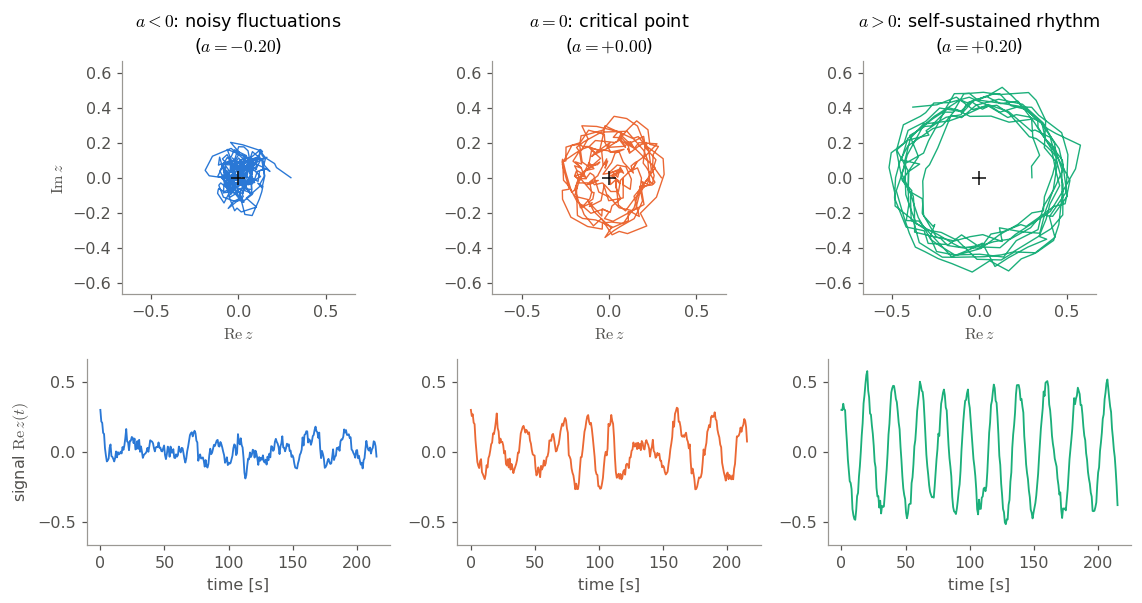

In [3]:
def simulate(model, z0, n_frames, seed=0):
    # Solve the stochastic differential equation for n_frames brain images: (batch, regions, time)
    seed_all(seed)
    with torch.no_grad():
        return model(z0, n_steps=n_frames, dt=TR, dt_min=DT)

one_region = {a: CoupledHopfModel(n_rois=1, initial_a=a, initial_kappa=1.0, noise_sigma=0.05,
                                  omega=torch.tensor([2 * math.pi * 0.05]))     # one cycle every 20 s
              for a in (-0.2, 0.0, 0.2)}
P.regimes(TR, {a: simulate(m, torch.full((1, 1), 0.3 + 0j), 300)[0, 0] for a, m in one_region.items()})

Below the critical point ($a<0$) the region is silent on its own, and noise produces irregular bursts that keep dying out. Above it ($a>0$) it beats like a metronome. Whole-brain models reproduce fMRI best when each region is tuned **just below** the critical point, $a\approx 0^-$, where noise is enough to produce rich, irregular but structured activity [4, 5].

### 4.3 Many oscillators wired together: the Coupled Hopf model

Now we put one oscillator in every region and connect them through the connectome. This is the **Coupled Hopf model**, one of the most widely used whole-brain models [4, 5]:

$$
\mathrm{d}z_i=\Big[\underbrace{\big(a+i\omega_i-|z_i|^2\big)z_i}_{\text{local oscillator}}
+\underbrace{G\sum_{j=1}^{n} C_{ij}\big(z_j-z_i\big)}_{\text{coupling}}\Big]\mathrm{d}t
+\sigma\,\mathrm{d}W_i ,
\qquad i=1,\dots,n.
$$

| Symbol | Meaning |
|---|---|
| $a$ | bifurcation parameter: how close each region is to oscillating on its own |
| $\omega_i$ | natural rhythm of region $i$ (here between 0.04 and 0.07 Hz, i.e. one cycle every 14–25 s) |
| $G$ | global coupling: one number that scales all connections |
| $C_{ij}$ | the fixed anatomical wiring (row-normalised connectome) |
| $\sigma$, $W_i$ | noise level and independent complex Brownian motions |

The coupling term pulls each region towards its neighbours, a bit like metronomes standing on a shared table that slowly fall into step [28]. The model has only a handful of parameters, and **each one has a clear meaning**.

We now choose "true" parameters and record 16 scans of 7.2 minutes from our virtual brain. Only the real part $\mathrm{Re}\,z_i(t)$ plays the role of the BOLD signal that a scanner would measure.

16 scans, 20 regions, 600 images (7.2 min) each


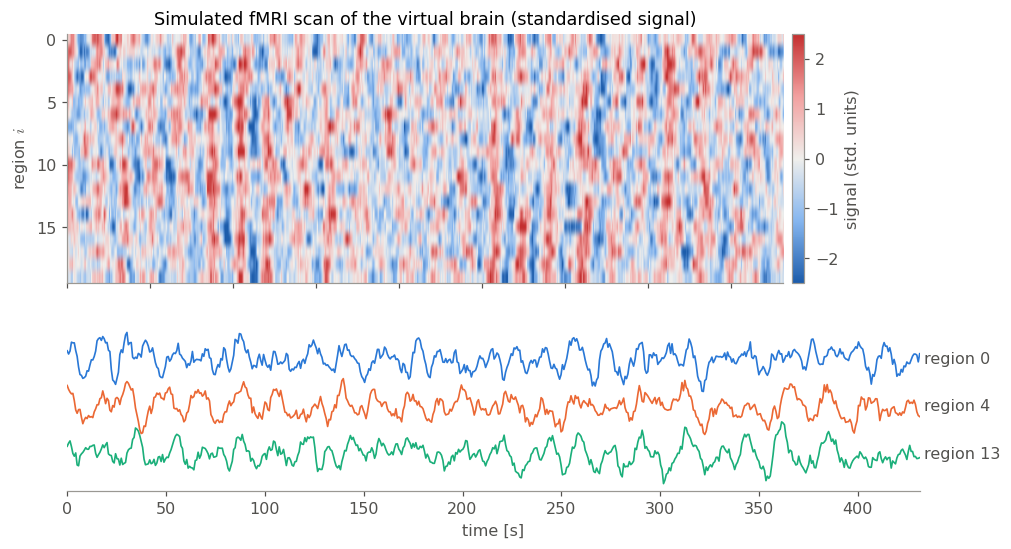

In [4]:
seed_all(1)
omega = 2 * math.pi * (0.04 + 0.03 * torch.rand(20))          # natural rhythms, 0.04-0.07 Hz
truth = dict(initial_a=-0.02, initial_g=0.2, initial_kappa=1.0, noise_sigma=0.02)
virtual_brain = CoupledHopfModel(20, C, omega=omega, **truth)

z_true = simulate(virtual_brain, torch.full((16, 20), 0.05 + 0j), 750, seed=1)[:, :, 150:]   # drop warm-up
bold = z_true.real                                            # what the scanner sees
print(f"{bold.shape[0]} scans, {bold.shape[1]} regions, {bold.shape[2]} images ({bold.shape[2] * TR / 60:.1f} min) each")
P.scan(TR, bold[0])

Apart from some fast jitter added by the noise (the preprocessing below removes it), the simulated scan already resembles the real one in Section 3: slow waves, and groups of regions that rise and fall together.

## 5. From a real signal to a complex one

A scanner gives a real number per region and time, but our models live in the complex plane, with an amplitude and a phase. The bridge is a standard three-step preprocessing [1, 18]:

1. **Standardise** each region: $\tilde x_i=(x_i-\mu_i)/\sigma_i$, so that all regions have mean 0 and variance 1.
2. **Band-pass filter** to keep only the slow fluctuations between 0.008 and 0.08 Hz, where resting-state activity lives.
3. **Hilbert transform**: complete the real signal $x$ with an imaginary part $\mathcal{H}[x]$, its "quarter-period-shifted" copy, to form the **analytic signal**
$$z(t)=x(t)+i\,\mathcal{H}[x](t)=A(t)\,e^{i\phi(t)},$$
whose modulus $A(t)$ is the instantaneous amplitude and whose angle $\phi(t)$ is the instantaneous phase. In Fourier terms, $\mathcal{H}$ multiplies positive frequencies by $-i$ and negative ones by $+i$.

Our virtual brain gives us a rare luxury: we *know* the hidden imaginary part, so we can check how well this recipe recovers it.

Phase agreement with the hidden truth: 0.89   (1 = perfect, 0 = unrelated)


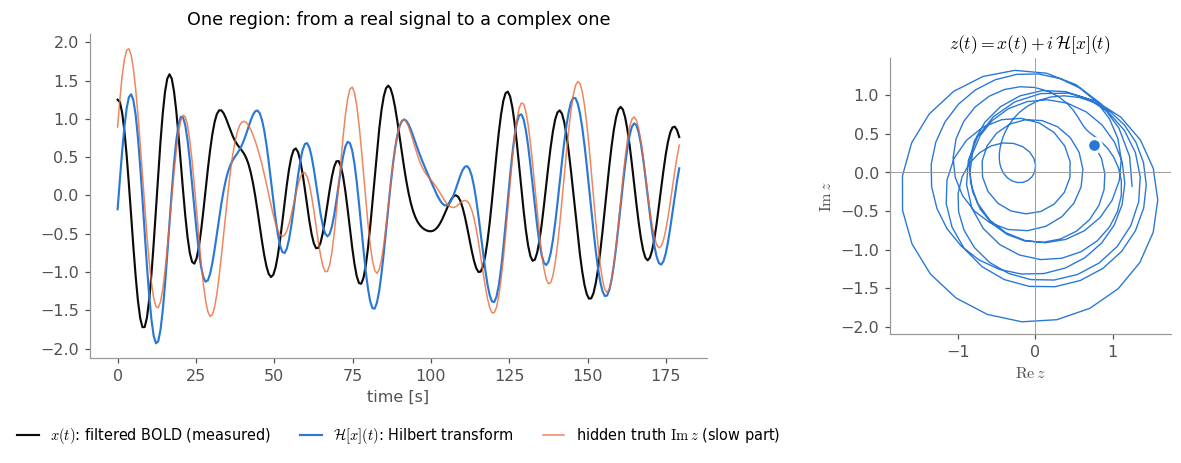

In [5]:
x = (bold - bold.mean(-1, keepdim=True)) / bold.std(-1, keepdim=True)   # 1. standardise
x = fft_bandpass_3d(x, dt=TR, f_lo=0.008, f_hi=0.08)                   # 2. band-pass filter
z = hilbert_transform(x)                                                # 3. analytic signal

# compare with the slow part of the hidden truth (the filter removes fast noise on purpose)
slow = lambda s: fft_bandpass_3d(s, dt=TR, f_lo=0.008, f_hi=0.08)
slow_truth = torch.complex(slow(z_true.real), slow(z_true.imag))
agreement = torch.cos(z.angle() - slow_truth.angle()).mean()
print(f"Phase agreement with the hidden truth: {agreement:.2f}   (1 = perfect, 0 = unrelated)")
P.analytic(TR, z[0, 0], slow_truth[0, 0])

From the real part alone, the Hilbert transform recovers the phase of the slow activity very well (the filter deliberately discards the fast jitter that the noise adds on top). This is why, with real data, we can treat the preprocessed fMRI signal as the complex state $z(t)$ of an oscillator model. **From now on we work with the virtual brain's complex state `z_true`**, which is exactly what this pipeline estimates.

## 6. A fingerprint of brain activity: functional connectivity

Brain activity is noisy, so two scans of the same person never look alike moment by moment. What *is* reproducible are its **statistics**. The most popular one is **functional connectivity** (FC) [15]: for every pair of regions, how strongly do their signals go up and down together? With $\tilde x_i$ the standardised real part of region $i$,

$$\mathrm{FC}_{ij}(z)=\frac1T\int_0^T\tilde x_i(t)\,\tilde x_j(t)\,\mathrm{d}t \;\in[-1,1],$$

the correlation coefficient between regions $i$ and $j$. FC is the "who moves together with whom" map of the brain. Neuroscientists use several other descriptors, all built from the same ingredients [1]:

| Descriptor | What it captures | Definition |
|---|---|---|
| **phase FC** (phFC) | do the rhythms of two regions keep a fixed phase difference? [17] | $\frac1T\int_0^T\cos\big(\phi_i(t)-\phi_j(t)\big)\,\mathrm{d}t$ |
| **FCD** | how the FC pattern itself changes over time [16] | correlation between FC matrices computed in sliding windows |
| **phase FCD** (phFCD) | the same for instantaneous phase patterns [18] | cosine similarity between phase-coherence patterns at times $t$, $t'$ |
| **metastability** | how much global synchrony fluctuates [2, 4] | standard deviation in time of $R(t)=\big\lvert\frac1n\sum_k e^{i\phi_k(t)}\big\rvert$ |

Here we focus on FC. Let us compare it with the wiring of our virtual brain.

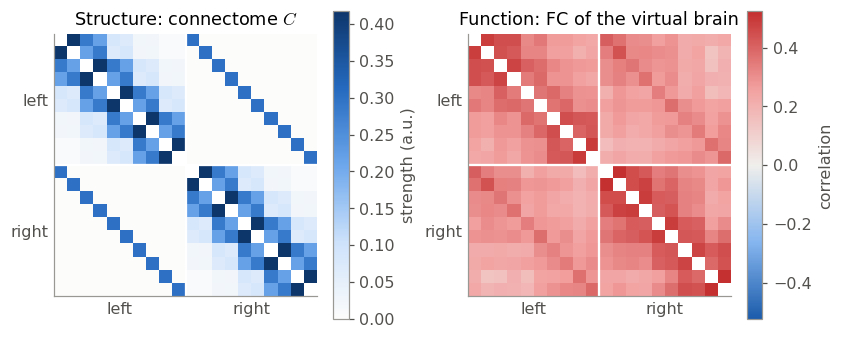

similarity(C, FC) = 0.86


In [6]:
def similarity(A, B):
    # Pearson correlation between the off-diagonal entries of two matrices
    i, j = torch.triu_indices(len(A), len(A), 1)
    return torch.corrcoef(torch.stack([A[i, j], B[i, j]]))[0, 1].item()

fc_true = compute_static_fc(z_true).mean(0)       # FC of each scan, averaged over the 16 scans
P.matrices([C, fc_true], ["Structure: connectome $C$", "Function: FC of the virtual brain"], kinds=["sc", "fc"])
print(f"similarity(C, FC) = {similarity(C, fc_true):.2f}")

FC resembles the wiring, but it is not a copy: regions that are not directly connected can still be strongly correlated through common neighbours, and the two hemispheres move together thanks to a few mirror links. *Structure shapes function*, but the dynamics matter.

### 6.1 The coupling knob $G$

How much does FC depend on the single parameter $G$? We simulate the same brain with no coupling, with the true coupling and with a very strong one, all starting from the same states as the 16 recorded scans.

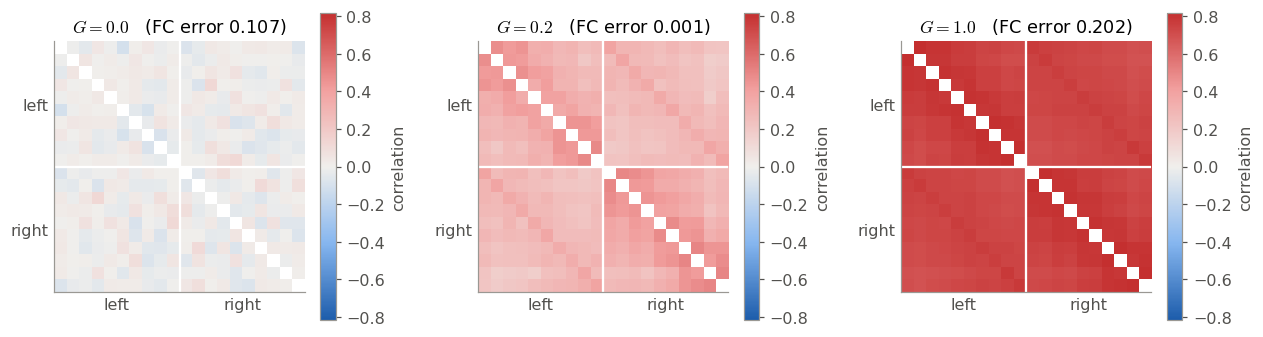

In [7]:
runs = {G: simulate(CoupledHopfModel(20, C, omega=omega, **{**truth, "initial_g": G}),
                    z_true[:, :, 0], 600, seed=2)
        for G in (0.0, 0.2, 1.0)}
fc_error = FCMSE()                                   # mean-squared difference between FC matrices
P.matrices([compute_static_fc(run).mean(0) for run in runs.values()],
           [f"$G={G}$   (FC error {fc_error(run, z_true):.3f})" for G, run in runs.items()])

With $G=0$ the regions ignore each other and FC is just noise. With a strong coupling everything synchronises and all correlations crowd towards 1: the pattern is still visible, but at the wrong level. Only in between do we recover the FC of the virtual brain (lowest error). Because the *pattern* and the *level* of FC can go wrong separately, the objective we use for training measures both (their correlation and their mean-squared error). Classically, whole-brain models are fitted by scanning a grid of values of $a$ and $G$ and keeping the best one [4, 5]. Finding the right numbers, though, requires first answering a deeper question.

## 7. How do we know a model is good? The $L^2$ trap

The most obvious way to compare a simulation $\hat z_\theta$ with a recording $z$ is to measure the distance between the two curves, the **mean-squared ($L^2$) error**. It is the default in curve fitting and in much of machine learning:

$$\mathcal{L}(\theta)=\mathbb{E}\,\big\lVert\hat z_\theta-z\big\rVert^2_{L^2(0,T)}.$$

For a *stochastic* model this is a trap. Expanding the square,

$$\mathbb{E}\lVert\hat z_\theta-z\rVert^2=\mathbb{E}\lVert\hat z_\theta\rVert^2+\mathbb{E}\lVert z\rVert^2-2\,\mathbb{E}\langle\hat z_\theta,z\rangle
\;\approx\;\mathbb{E}\lVert\hat z_\theta\rVert^2+\mathbb{E}\lVert z\rVert^2 ,$$

because the model is driven by its own noise, independent of the noise that drove the real brain, and the signals have mean zero: after a short transient the cross term vanishes. What is left only rewards the model for being **quiet**. A perfect copy of the brain scores about $2\,\mathbb{E}\lVert z\rVert^2$, while a model that does nothing scores $\mathbb{E}\lVert z\rVert^2$ and **wins**.

Think of weather forecasting: a simulator judged on whether it predicts the exact temperature of a random day next year would be beaten by one that always predicts "average weather, no wind". For random systems we must compare their *climate*, not individual days.

Let us check this with three candidate models, all started from the same states as the 16 scans:

* **twin** — exactly the virtual brain, with fresh noise (the perfect model);
* **rewired** — the same equations and connections, but plugged into the wrong regions;
* **silent** — no noise and no coupling: every region simply fades away to zero.

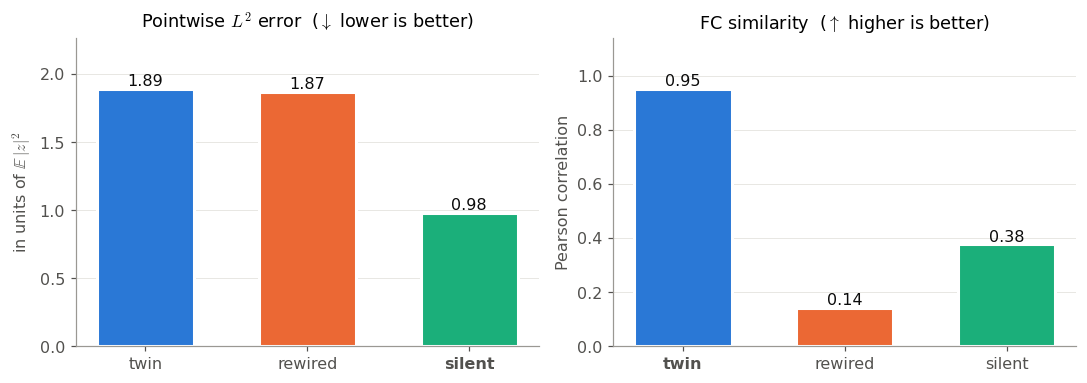

In [8]:
perm = torch.randperm(20, generator=torch.Generator().manual_seed(3))
z0 = z_true[:, :, 0]
candidates = {
    "twin": runs[0.2],
    "rewired": simulate(CoupledHopfModel(20, C[perm][:, perm], omega=omega, **truth), z0, 600, seed=2),
    "silent": simulate(CoupledHopfModel(20, C, omega=omega,
                                        **{**truth, "initial_a": -0.1, "initial_g": 0.0, "noise_sigma": 0.0}), z0, 600),
}
l2_error, fc_loss = L2Timeseries(), FCCorrelation()           # the same loss terms used in our training code
energy = z_true.abs().pow(2).mean()
P.scores({name: (l2_error(sim, z_true) / energy, 1 - fc_loss(sim, z_true)) for name, sim in candidates.items()})

The pointwise $L^2$ error picks the **silent** model, which has nothing to do with a brain, and it cannot tell the twin from the rewired brain. FC similarity ranks the candidates correctly.

**The right objective compares statistics of the law, not paths.** We therefore fit models with a weighted sum of distances between descriptors $\Phi_k$ (FC, phase FC, FCD, phase FCD, amplitude, frequency, metastability):

$$\mathcal{L}(\theta)=\sum_{k=1}^{m} w_k\; d_k\Big(\Phi_k(\hat z_\theta),\,\Phi_k(z)\Big)\;+\;\lambda\,\mathcal{R}(\theta).$$

We ask two things of every descriptor:

* **noise-invariant** — it is a property of the *law* of the process, not of the particular noise realisation, so the objective is well posed for a random model;
* **differentiable** — so that the gradient $\nabla_\theta\mathcal{L}$ can be computed by backpropagating through the equation solver, and the parameters improved step by step with gradient descent, $\theta_{k+1}=\theta_k-\eta\,\nabla_\theta\mathcal{L}$ [19, 20].

Some classical descriptors, such as the Kolmogorov–Smirnov distance between FCD distributions, are not differentiable; in the paper we train on smooth surrogates and keep the classical versions for evaluation [1]. A small regulariser $\mathcal R$ that matches the joint distribution of the signal at pairs of times [22] completes the objective. Gradient descent costs a fixed number of simulations per update, *whatever the number of parameters*, whereas a grid search grows exponentially with it. This is what makes richer models trainable.

## 8. Physics or machine learning? Three architectures

The Coupled Hopf model is interpretable and needs little data, but it is **rigid**: one global $G$ and a fixed wiring cannot express everything real brains do. At the other extreme, machine learning offers **Neural Stochastic Differential Equations** [19–21], in which neural networks $f_\theta$ and $g_\phi$ learn both the deterministic part (drift) and the noise (diffusion) directly from data:

$$\mathrm{d}z(t)=f_\theta\big(z(t)\big)\,\mathrm{d}t+g_\phi\big(z(t)\big)\,\mathrm{d}W(t),\qquad f_\theta,\,g_\phi:\mathbb{C}^n\to\mathbb{C}^n .$$

They can approximate almost any dynamics, but they have no built-in notion of rhythm or anatomy: they need much more data, and none of their parameters means anything.

| | Coupled Hopf (physics) | Neural SDE (data-driven) |
|---|---|---|
| Data fidelity | ✗ too rigid | ✓ flexible |
| Data efficiency | ✓ few parameters | ✗ data hungry |
| Interpretability | ✓ physical model | ✗ black box |

**Can we keep the best of both worlds?** Hybrid modelling, already successful in other sciences [23, 24], says yes: keep the equations we trust and learn only the part we do not know well. In the brain, the local oscillator is well established, whereas *how regions influence each other* is far less certain: real synapses are nonlinear, and effective interactions depart from the anatomical wiring. Our **Hybrid Hopf model** [1] therefore keeps the oscillator and replaces the fixed coupling by a small learned network:

$$
m_i=\sum_{j=1}^{n} C_{ij}\big(k_j-k_i\big),\quad k_j=\varphi_{\mathrm{key}}(z_j),
\qquad
\mathrm{d}z_i=\Big[\big(a+i\omega_i-|z_i|^2\big)z_i+G\,\psi_{\mathrm{out}}(m_i,z_i)\Big]\mathrm{d}t+\sigma\,\mathrm{d}W_i .
$$

Each region encodes its state into a short "message" $k_j$ (the network $\varphi_{\mathrm{key}}$), messages are collected along a **learnable** wiring $C$ that starts from the connectome, and a second network $\psi_{\mathrm{out}}$ turns the incoming message into a push on the oscillator. Both networks are tiny and shared by all regions.

![The three architectures](img/architectures.jpg)

*The three model families, from interpretable to flexible. Figure from [1].*

All three models are available in our package with the same interface. Let us create them at the size used in the paper (100 regions) and count how many numbers each one learns:

In [9]:
n = 100
models = {"Coupled Hopf": CoupledHopfModel(n),
          "Hybrid Hopf": HybridHopfModel(n, learnable_kappa=False),
          "Neural SDE": NeuralSDE(n, hidden_dim=256)}
for name, model in models.items():
    print(f"{name:13s} {sum(p.numel() for p in model.parameters() if p.requires_grad):>8,} learnable parameters")

Coupled Hopf         2 learnable parameters
Hybrid Hopf      2,215 learnable parameters
Neural SDE     220,176 learnable parameters


The Coupled Hopf model learns only $a$ and $G$. The Hybrid Hopf model learns about two thousand numbers, mostly the wiring $C$ (stored compactly as a low-rank product $C = LR^\top$ initialised from the functional connectome). The Neural SDE learns over two hundred thousand.

## 9. What happens with real brains

In the paper [1] we trained the three models with the objective of Section 7 on resting-state fMRI from 94 subjects of the Human Connectome Project (100 regions), and evaluated them on held-out subjects. *The numbers below are taken from the paper; they are not computed in this notebook.*

| Model | FC corr ↑ | phase FC corr ↑ | FCD KS ↓ | phase FCD KS ↓ | metastability error ↓ | composite error ↓ |
|---|---|---|---|---|---|---|
| Coupled Hopf | 0.913 ± 0.011 | 0.783 ± 0.021 | 0.242 ± 0.009 | 0.208 ± 0.092 | **0.010 ± 0.005** | 0.189 ± 0.023 |
| Neural SDE | 0.787 ± 0.265 | 0.729 ± 0.329 | 0.145 ± 0.133 | 0.217 ± 0.065 | 0.037 ± 0.047 | 0.211 ± 0.163 |
| **Hybrid Hopf** | **0.926 ± 0.010** | **0.923 ± 0.014** | **0.100 ± 0.019** | **0.101 ± 0.041** | **0.010 ± 0.005** | **0.088 ± 0.010** |

*Mean ± standard deviation over 10 independent trainings. "corr" is the correlation between simulated and empirical matrices (higher is better); "KS" is the Kolmogorov–Smirnov distance between distributions (lower is better); the composite error averages the four core descriptors.*

![Empirical and simulated activity on the cortex](img/models.gif)

*Brain activity painted on the cortex, for a real recording and for the three trained models. Figure from [1].*

The physics-based model is stable but cannot reproduce phase relations and dynamics. The Neural SDE is flexible but unreliable: some trainings fail completely, which explains its large spread. **The hybrid model is the only one that is both accurate and reproducible**, while keeping an oscillator whose parameters still have a meaning. In summary:

| | Coupled Hopf | Hybrid Hopf | Neural SDE |
|---|---|---|---|
| Reproduces network structure (FC, phase FC) | ∼ partly | ✓ | ∼ unstable across trainings |
| Reproduces network dynamics (FCD, phase FCD) | ✗ | ✓ | ∼ partly |
| Interpretable parameters | ✓ | ✓ | ✗ |
| Uses the functional connectome | ✓ | ✓ | ✗ |
| Works with little data (10 subjects) | ✓ | ✓ | ✗ |
| Captures the individual (1 subject) | ✗ | ✓ | ✓ |
| Learnable parameters | 2 | ≈ 2 200 | ≈ 220 000 |

## 10. Open questions

* **Many objectives at once.** With fixed weights $w_k$, the loss $\sum_k w_k d_k$ picks one point on a *Pareto front* of trade-offs between descriptors. Which point should we pick, and can we explore the whole front?
* **Control.** The clinical goal is stimulation: add an input $Bu(t)$ to the drift and ask whether the brain can be steered (controllability), with which protocol (optimal control), and with feedback in closed loop. Does a learned model react to stimulation like the real brain, i.e. does it preserve the sensitivity $\partial_u y$?
* **From regions to neurons and back.** As the number of neurons goes to infinity, mass models should reconnect to the neural field equations they came from. What does the learned system do as $t\to\infty$?
## References

1. D. López-Montero, L. Liverani, E. Zuazua, X. Kobeleva. *Hybrid generative models of whole-brain dynamics balance data fidelity and interpretability.* Manuscript under review (2026). Code: [github.com/DCN-FAU-AvH/neuroscience-modeling](https://github.com/DCN-FAU-AvH/neuroscience-modeling).
2. G. Deco, V. K. Jirsa, A. R. McIntosh. Emerging concepts for the dynamical organization of resting-state activity in the brain. *Nat. Rev. Neurosci.* 12, 43–56 (2011). [doi:10.1038/nrn2961](https://doi.org/10.1038/nrn2961)
3. M. Breakspear. Dynamic models of large-scale brain activity. *Nat. Neurosci.* 20, 340–352 (2017). [doi:10.1038/nn.4497](https://doi.org/10.1038/nn.4497)
4. G. Deco, M. L. Kringelbach, V. K. Jirsa, P. Ritter. The dynamics of resting fluctuations in the brain: metastability and its dynamical cortical core. *Sci. Rep.* 7, 3095 (2017). [doi:10.1038/s41598-017-03073-5](https://doi.org/10.1038/s41598-017-03073-5)
5. A. Ponce-Alvarez, G. Deco. The Hopf whole-brain model and its linear approximation. *Sci. Rep.* 14, 2615 (2024). [doi:10.1038/s41598-024-53105-0](https://doi.org/10.1038/s41598-024-53105-0)
6. H. R. Wilson, J. D. Cowan. Excitatory and inhibitory interactions in localized populations of model neurons. *Biophys. J.* 12, 1–24 (1972). [doi:10.1016/S0006-3495(72)86068-5](https://doi.org/10.1016/S0006-3495%2872%2986068-5)
7. S. Amari. Dynamics of pattern formation in lateral-inhibition type neural fields. *Biol. Cybern.* 27, 77–87 (1977). [doi:10.1007/BF00337259](https://doi.org/10.1007/BF00337259)
8. A. L. Hodgkin, A. F. Huxley. A quantitative description of membrane current and its application to conduction and excitation in nerve. *J. Physiol.* 117, 500–544 (1952). [doi:10.1113/jphysiol.1952.sp004764](https://doi.org/10.1113/jphysiol.1952.sp004764)
9. D. O. Hebb. *The Organization of Behavior.* Wiley (1949).
10. F. Rosenblatt. The perceptron: a probabilistic model for information storage and organization in the brain. *Psychol. Rev.* 65, 386–408 (1958). [doi:10.1037/h0042519](https://doi.org/10.1037/h0042519)
11. S. Ogawa, T. M. Lee, A. R. Kay, D. W. Tank. Brain magnetic resonance imaging with contrast dependent on blood oxygenation. *PNAS* 87, 9868–9872 (1990). [doi:10.1073/pnas.87.24.9868](https://doi.org/10.1073/pnas.87.24.9868)
12. N. K. Logothetis et al. Neurophysiological investigation of the basis of the fMRI signal. *Nature* 412, 150–157 (2001). [doi:10.1038/35084005](https://doi.org/10.1038/35084005)
13. S. M. Smith et al. Resting-state fMRI in the Human Connectome Project. *NeuroImage* 80, 144–168 (2013). [doi:10.1016/j.neuroimage.2013.05.039](https://doi.org/10.1016/j.neuroimage.2013.05.039)
14. A. Schaefer et al. Local-global parcellation of the human cerebral cortex from intrinsic functional connectivity MRI. *Cereb. Cortex* 28, 3095–3114 (2018). [doi:10.1093/cercor/bhx179](https://doi.org/10.1093/cercor/bhx179)
15. B. Biswal et al. Functional connectivity in the motor cortex of resting human brain using echo-planar MRI. *Magn. Reson. Med.* 34, 537–541 (1995). [doi:10.1002/mrm.1910340409](https://doi.org/10.1002/mrm.1910340409)
16. E. C. A. Hansen et al. Functional connectivity dynamics: modeling the switching behavior of the resting state. *NeuroImage* 105, 525–535 (2015). [doi:10.1016/j.neuroimage.2014.11.001](https://doi.org/10.1016/j.neuroimage.2014.11.001)
17. E. Glerean et al. Functional magnetic resonance imaging phase synchronization as a measure of dynamic functional connectivity. *Brain Connect.* 2, 91–101 (2012). [doi:10.1089/brain.2011.0068](https://doi.org/10.1089/brain.2011.0068)
18. G. Deco et al. Awakening: predicting external stimulation to force transitions between different brain states. *PNAS* 116, 18088–18097 (2019). [doi:10.1073/pnas.1905534116](https://doi.org/10.1073/pnas.1905534116)
19. R. T. Q. Chen, Y. Rubanova, J. Bettencourt, D. Duvenaud. Neural ordinary differential equations. *NeurIPS* (2018). [arXiv:1806.07366](https://arxiv.org/abs/1806.07366)
20. X. Li, T.-K. L. Wong, R. T. Q. Chen, D. Duvenaud. Scalable gradients for stochastic differential equations. *AISTATS*, PMLR 108, 3870–3882 (2020).
21. P. Kidger, J. Foster, X. Li, T. Lyons. Neural SDEs as infinite-dimensional GANs. *ICML*, PMLR 139, 5453–5463 (2021).
22. J. Zhang, J. Viktorov, D. Jung, E. Pitler. Efficient training of neural stochastic differential equations by matching finite dimensional distributions. *ICLR* (2025). [arXiv:2410.03973](https://arxiv.org/abs/2410.03973)
23. G. E. Karniadakis et al. Physics-informed machine learning. *Nat. Rev. Phys.* 3, 422–440 (2021). [doi:10.1038/s42254-021-00314-5](https://doi.org/10.1038/s42254-021-00314-5)
24. C. Rackauckas et al. Universal differential equations for scientific machine learning. [arXiv:2001.04385](https://arxiv.org/abs/2001.04385) (2020).
25. P. Sanz Leon et al. The Virtual Brain: a simulator of primate brain network dynamics. *Front. Neuroinform.* 7, 10 (2013). [doi:10.3389/fninf.2013.00010](https://doi.org/10.3389/fninf.2013.00010)
26. V. Jirsa et al. Personalised virtual brain models in epilepsy. *Lancet Neurol.* 22, 443–454 (2023). [doi:10.1016/S1474-4422(23)00008-X](https://doi.org/10.1016/S1474-4422%2823%2900008-X)
27. M. Ercsey-Ravasz et al. A predictive network model of cerebral cortical connectivity based on a distance rule. *Neuron* 80, 184–197 (2013). [doi:10.1016/j.neuron.2013.07.036](https://doi.org/10.1016/j.neuron.2013.07.036)
28. J. Pantaleone. Synchronization of metronomes. *Am. J. Phys.* 70, 992–1000 (2002). [doi:10.1119/1.1501118](https://doi.org/10.1119/1.1501118)
29. S. H. Strogatz. *Nonlinear Dynamics and Chaos*, 2nd ed. Westview Press (2015).
30. S. Ramón y Cajal. The structure and connexions of neurons. Nobel Lecture, 12 December 1906. [nobelprize.org](https://www.nobelprize.org/prizes/medicine/1906/cajal/lecture/)
